Consensus reached at step 28


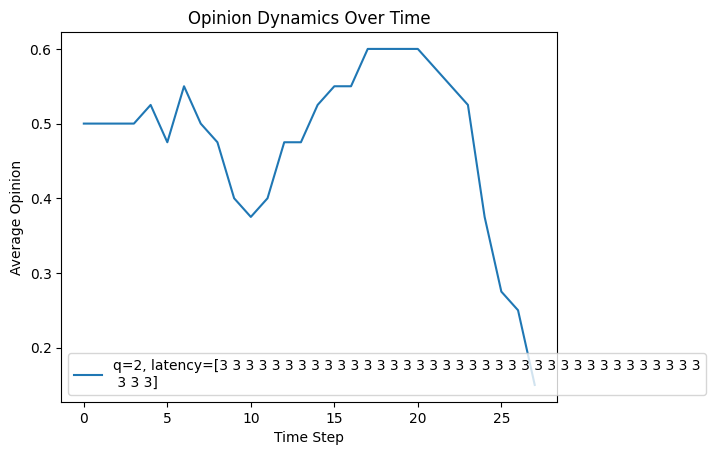

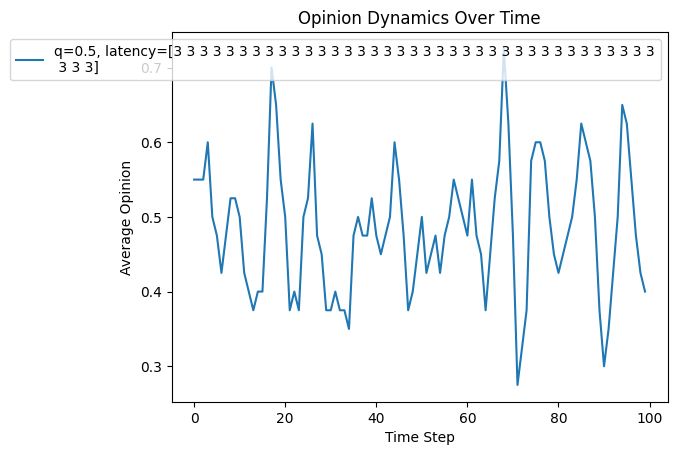

Consensus reached at step 38


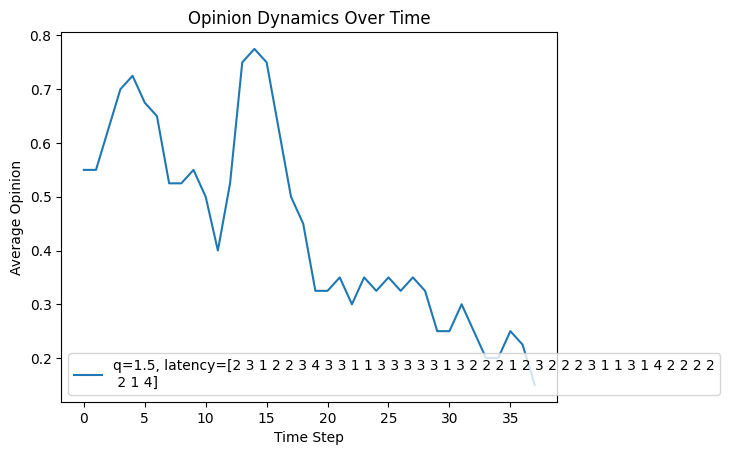

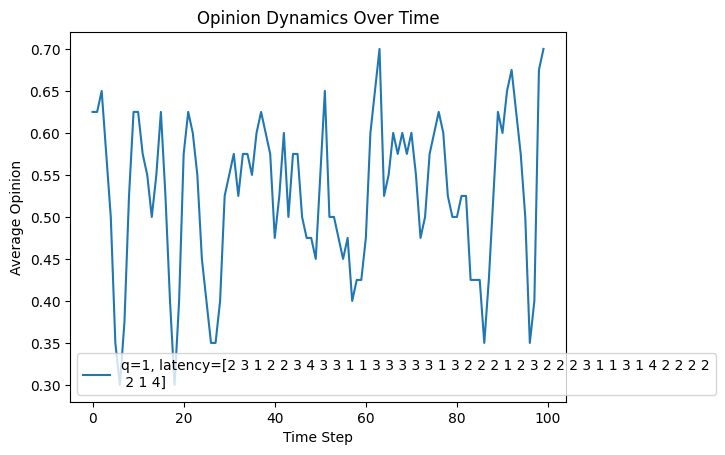

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt

# Set the random seed for reproducibility
np.random.seed(42)

class VoterModel:
    def __init__(self, num_nodes, hyperedges, q, latency, consensus_threshold):
        self.num_nodes = num_nodes
        self.hyperedges = hyperedges
        self.q = q
        self.latency = latency  # Either fixed or a distribution
        self.consensus_threshold = consensus_threshold
        self.opinions = np.random.choice([0, 1], size=num_nodes)
        self.last_change_time = np.zeros(num_nodes, dtype=int)
        self.time_step = 0
        self.history = []

    def influence_score(self, opinion, edge):
        return sum(1 for node in edge if self.opinions[node] == opinion)

    def update_opinion(self):
        new_opinions = self.opinions.copy()
        for edge in self.hyperedges:
            s0 = self.influence_score(0, edge) ** self.q
            s1 = self.influence_score(1, edge) ** self.q
            for node in edge:
                if self.time_step - self.last_change_time[node] >= self.latency[node]:
                    p1 = s1 / (s0 + s1) if s0 + s1 > 0 else 0.5
                    new_opinions[node] = 1 if random.random() < p1 else 0
                    if new_opinions[node] != self.opinions[node]:
                        self.last_change_time[node] = self.time_step
        self.opinions = new_opinions

    def check_consensus(self):
        majority_opinion = np.mean(self.opinions)
        return majority_opinion >= self.consensus_threshold or majority_opinion <= 1 - self.consensus_threshold

    def run(self, max_steps=100):
        for self.time_step in range(1, max_steps + 1):
            self.history.append(np.mean(self.opinions))
            if self.check_consensus():
                print(f"Consensus reached at step {self.time_step}")
                break
            self.update_opinion()
        return self.history

    def plot_history(self):
        plt.plot(self.history, label=f'q={self.q}, latency={self.latency}')
        plt.xlabel("Time Step")
        plt.ylabel("Average Opinion")
        plt.title("Opinion Dynamics Over Time")
        plt.legend()
        plt.show()

# Parameters for Test Cases
num_nodes = 40
hyperedges = [random.sample(range(num_nodes), k=random.randint(6, 10)) for _ in range(6)]
consensus_threshold = 0.8
max_steps = 100

# Test Case 1: Strong Majority Influence
q_high = 2
latency_fixed = np.full(num_nodes, 3)
model1 = VoterModel(num_nodes, hyperedges, q=q_high, latency=latency_fixed, consensus_threshold=consensus_threshold)
history1 = model1.run(max_steps=max_steps)
model1.plot_history()

# Test Case 2: Minority Persistence
q_low = 0.5
latency_fixed = np.full(num_nodes, 3)
model2 = VoterModel(num_nodes, hyperedges, q=q_low, latency=latency_fixed, consensus_threshold=consensus_threshold)
history2 = model2.run(max_steps=max_steps)
model2.plot_history()

# latency
latency_variable = np.random.randint(1, 6, size=num_nodes)
latency_mixed = np.random.randint(2, 4, size=num_nodes)
latency_gassian1 = np.clip(np.random.normal(3,1,size=num_nodes), 1, None).astype(int)
latency_gassian2 = np.clip(np.random.normal(3,2,size=num_nodes), 1, None).astype(int)

# Test Case 3: Oscillatory Dynamics
q_moderate = 1.5
model3 = VoterModel(num_nodes, hyperedges, q=q_moderate, latency=latency_gassian1, consensus_threshold=consensus_threshold)
history3 = model3.run(max_steps=max_steps)
model3.plot_history()

# Test Case 4: Mixed Influence and Latency
q_moderate = 1
model4 = VoterModel(num_nodes, hyperedges, q=q_moderate, latency=latency_gassian1, consensus_threshold=consensus_threshold)
history4 = model4.run(max_steps=max_steps)
model4.plot_history()
